In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np  

###  Customers

In [2]:
customers = pd.read_csv('data_challenge_account.csv')

In [3]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 55084 entries, 0 to 55083
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 55084 non-null  str    
 1   parent_account     27677 non-null  str    
 2   billing_address    55084 non-null  str    
 3   shipping_address   55084 non-null  str    
 4   klienten_bewohner  0 non-null      float64
 5   renewal_model      54703 non-null  str    
 6   category           52228 non-null  str    
 7   number_patients    36434 non-null  float64
 8   business_unit      54293 non-null  str    
dtypes: float64(2), str(7)
memory usage: 3.8 MB


In [4]:
customers.head()

,id,parent_account,billing_address,shipping_address,klienten_bewohner,renewal_model,category,number_patients,business_unit
0,AE32A4C0DD9DB7905CFE0,NaN,48EF650E8F4B7B5135ABC,48EF650E8F4B7B5135ABC,NaN,Contract Based,Einzelunternehmung,NaN,MediFoxTherapy
1,128853ABCD045C35FFB4A,09EC304D2B7F4F7B2C018,F5F3E1546F56671195A29,194C28A9C4412B042B925,NaN,Contract Based,Trägerzugehöriger Mandant,NaN,MediFoxStationary
2,C22C9EC1C28ABAB6FEE3D,NaN,670B96CF3750BAFB661EA,670B96CF3750BAFB661EA,NaN,Contract Based,Einzelunternehmung,NaN,MediFoxTherapy
3,D5E5FCF8284E743E216E9,7D6FF27C52747C1F52E44,B94683690836F114C9AF2,B94683690836F114C9AF2,NaN,Contract Based,Trägerzugehöriger Mandant,0.0,MediFoxStationary
4,0D6E34A39E35178200A9C,FD6538769892A41F84AEB,B8DA74B4B1F3F43F4B369,B8DA74B4B1F3F43F4B369,NaN,Contract Based,Trägerzugehöriger Mandant,NaN,MediFoxStationary


In [5]:
customers.groupby('parent_account')['id'].count().sort_values(ascending=False)

parent_account
10C97E20271E4DCA87372    288
9CEFD0CFA2E7A07780BAB    178
526857C8B9079C0FCF303    142
49AAD03652ADBDEE9FC62    140
68C0900D62040FCDBE868    138
                        ... 
FF142924A22FDADA07EB4      1
003C961257EC03DCEE333      1
FFDED36CE6F49AED35159      1
FFD61894EEB04AE91BA5C      1
FFD5B7DE80BA3B075DE1F      1
Name: id, Length: 6375, dtype: int64

In [6]:
customers['business_unit'].value_counts()

business_unit
MediFoxAmbulant       24920
MediFoxStationary     19633
MediFoxTherapy         8695
Jugendhilfe             706
IntegrationSupport      339
Name: count, dtype: int64

In [7]:
customers.renewal_model.value_counts()

renewal_model
Contract Based    54703
Name: count, dtype: int64

In [8]:
customers.category.value_counts()

category
Trägerzugehöriger Mandant    26064
Einzelunternehmung           18169
Träger                        7026
Privater Betreiber             634
OrganisationBranch             335
Name: count, dtype: int64

In [9]:
customers.query('number_patients > 50').number_patients.describe(percentiles = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.995,0.997])

count      3515.000000
mean        727.465718
std       10273.697987
min          51.000000
25%          80.000000
50%         101.000000
75%         150.000000
90%         250.000000
95%         350.000000
99%        2458.000000
99.5%      8090.000000
99.7%     80100.000000
max      300400.000000
Name: number_patients, dtype: float64

In [10]:
customers_with_parent = customers.merge(
    customers[['id', 'category', 'business_unit']],
    left_on='parent_account',
    right_on='id',
    how='left',
    suffixes=('', '_parent')
)

In [11]:
customers_with_parent.info()

<class 'pandas.DataFrame'>
RangeIndex: 55084 entries, 0 to 55083
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    55084 non-null  str    
 1   parent_account        27677 non-null  str    
 2   billing_address       55084 non-null  str    
 3   shipping_address      55084 non-null  str    
 4   klienten_bewohner     0 non-null      float64
 5   renewal_model         54703 non-null  str    
 6   category              52228 non-null  str    
 7   number_patients       36434 non-null  float64
 8   business_unit         54293 non-null  str    
 9   id_parent             27677 non-null  str    
 10  category_parent       27554 non-null  str    
 11  business_unit_parent  27625 non-null  str    
dtypes: float64(2), str(10)
memory usage: 5.0 MB


In [12]:
customers_with_parent.head()

,id,parent_account,billing_address,shipping_address,klienten_bewohner,renewal_model,category,number_patients,business_unit,id_parent,category_parent,business_unit_parent
0,AE32A4C0DD9DB7905CFE0,NaN,48EF650E8F4B7B5135ABC,48EF650E8F4B7B5135ABC,NaN,Contract Based,Einzelunternehmung,NaN,MediFoxTherapy,NaN,NaN,NaN
1,128853ABCD045C35FFB4A,09EC304D2B7F4F7B2C018,F5F3E1546F56671195A29,194C28A9C4412B042B925,NaN,Contract Based,Trägerzugehöriger Mandant,NaN,MediFoxStationary,09EC304D2B7F4F7B2C018,Träger,MediFoxStationary
2,C22C9EC1C28ABAB6FEE3D,NaN,670B96CF3750BAFB661EA,670B96CF3750BAFB661EA,NaN,Contract Based,Einzelunternehmung,NaN,MediFoxTherapy,NaN,NaN,NaN
3,D5E5FCF8284E743E216E9,7D6FF27C52747C1F52E44,B94683690836F114C9AF2,B94683690836F114C9AF2,NaN,Contract Based,Trägerzugehöriger Mandant,0.0,MediFoxStationary,7D6FF27C52747C1F52E44,Träger,MediFoxStationary
4,0D6E34A39E35178200A9C,FD6538769892A41F84AEB,B8DA74B4B1F3F43F4B369,B8DA74B4B1F3F43F4B369,NaN,Contract Based,Trägerzugehöriger Mandant,NaN,MediFoxStationary,FD6538769892A41F84AEB,Träger,MediFoxStationary


### Sales

In [13]:
sales = pd.read_csv('data_challenge_opportunity.csv')

In [14]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 62558 entries, 0 to 62557
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   record_type_name                 62304 non-null  str  
 1   id                               62558 non-null  str  
 2   closedate                        62558 non-null  str  
 3   account_id                       62558 non-null  str  
 4   lead_source                      60768 non-null  str  
 5   business_unit                    61789 non-null  str  
 6   opportunity_first_creation_date  62316 non-null  str  
dtypes: str(7)
memory usage: 3.3 MB


In [15]:
sales.record_type_name.value_counts()

record_type_name
ambulant            34286
stationär           11126
therapie             9149
Opportunity Tipp     6761
Jugendhilfe           982
Name: count, dtype: int64

In [16]:
sales.business_unit.value_counts()

business_unit
MediFoxAmbulant      38131
MediFoxStationary    12295
MediFoxTherapy       10382
Jugendhilfe            981
Name: count, dtype: int64

In [17]:
sales.lead_source.value_counts()

lead_source
LegacyLead                37049
Personal Contact          10459
Email                      5537
WebsiteContactForm         2172
Call                       1986
Other                      1694
Trade Show                  794
WebsiteAppointmentForm      239
MarketingCallSEO            201
Recommendation              117
Datasetacquisition          103
MarketingCallSEA             84
Recherche                    73
ColdCall                     72
DOL-Shop                     71
SalesrepColdVisit            40
Chat                         21
Visitor                      18
Partner Management           15
Webinar                       9
Ohne                          8
TakeoverOfTheCompany          5
DOL-Kontaktformular           1
Name: count, dtype: int64

### Products

In [18]:
products = pd.read_csv('data_challenge_opportunity_line_item.csv')

In [19]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 403378 entries, 0 to 403377
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                403378 non-null  str    
 1   opportunity_id    403378 non-null  str    
 2   product_id        403378 non-null  str    
 3   quantity          403378 non-null  float64
 4   discount          39732 non-null   float64
 5   subtotal          403330 non-null  float64
 6   totalprice        403378 non-null  float64
 7   unitprice         403330 non-null  float64
 8   listprice         403378 non-null  float64
 9   subscriptiontype  345335 non-null  str    
 10  enddate           399655 non-null  str    
 11  startdate         399660 non-null  str    
 12  product_category  403372 non-null  float64
 13  bundled           403378 non-null  bool   
dtypes: bool(1), float64(7), str(6)
memory usage: 40.4 MB


In [20]:
products.opportunity_id.nunique()

63243

In [21]:
products.product_category.value_counts( )

product_category
1.0     145180
2.0      82251
3.0      73216
4.0      40031
5.0      19210
8.0      15495
9.0       9239
7.0       6211
12.0      6172
6.0       5425
13.0       843
11.0        99
Name: count, dtype: int64

In [22]:
products.bundled.value_counts()

bundled
False    268219
True     135159
Name: count, dtype: int64

In [23]:
products.subscriptiontype.value_counts()

subscriptiontype
Renewable    345335
Name: count, dtype: int64

In [24]:
prd = products.copy()
prd['discount'] = prd.discount.fillna(0)
prd_subset = prd.loc[prd['subtotal'].round(0) != (prd['unitprice'] * prd['quantity']).round(0), :  ]
print(prd_subset.shape)
prd_subset.discount.describe()

(201, 14)


count    201.000000
mean       0.696517
std        7.583696
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      100.000000
Name: discount, dtype: float64

### Merging Data

In [25]:
df_merged = sales.merge(customers_with_parent, 
                        left_on='account_id', 
                        right_on='id', 
                        how='left', 
                        suffixes=('_sales', '_customers'))

In [26]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 62558 entries, 0 to 62557
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   record_type_name                 62304 non-null  str    
 1   id_sales                         62558 non-null  str    
 2   closedate                        62558 non-null  str    
 3   account_id                       62558 non-null  str    
 4   lead_source                      60768 non-null  str    
 5   business_unit_sales              61789 non-null  str    
 6   opportunity_first_creation_date  62316 non-null  str    
 7   id_customers                     62558 non-null  str    
 8   parent_account                   22496 non-null  str    
 9   billing_address                  62558 non-null  str    
 10  shipping_address                 62558 non-null  str    
 11  klienten_bewohner                0 non-null      float64
 12  renewal_model                

In [27]:
mask = (df_merged.business_unit_customers != df_merged.business_unit_sales)
mask.sum()


np.int64(1686)

In [121]:
df_all = products.merge(df_merged, 
                        left_on='opportunity_id', 
                        right_on='id_sales', 
                        how='inner', 
                        suffixes=('_products', '__opps'))

In [122]:
df_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 255328 entries, 0 to 255327
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   id                               255328 non-null  str    
 1   opportunity_id                   255328 non-null  str    
 2   product_id                       255328 non-null  str    
 3   quantity                         255328 non-null  float64
 4   discount                         38983 non-null   float64
 5   subtotal                         255280 non-null  float64
 6   totalprice                       255328 non-null  float64
 7   unitprice                        255280 non-null  float64
 8   listprice                        255328 non-null  float64
 9   subscriptiontype                 198887 non-null  str    
 10  enddate                          252170 non-null  str    
 11  startdate                        252170 non-null  str    
 12  product_categ

### Preprocessing

Products:
* Convert datetime: startdate, enddate (convert)
* products quantity and totalprice can not be negative (filter and remove)
* products enddate cannot be less than startdate (filter and remove)
* Products within a sale contract can have different delivery dates

Sales:
* convert datetime: closedate, opportunity_first_creation_date (convert)
* Remove rows with nan opportunity_first_creation_date
* Business unit replaced with customers business unit after merge

Customers:
* Customers with negative number of patients -> convert postive
* what is the median of customers nonzero number of patients
* renewal_model is Contract Based for all (with some missing values) -> drop
* klienten_bewohner all nan -> drop
* category, business_unit -> fill na with 'Unknown'



In [314]:
df = df_all.copy()

In [315]:
# Convert positive if number_patient is negeative
df['number_patients'] = df['number_patients'].abs()
df.number_patients = df.number_patients.fillna(0).astype(int)
# bin number of patients
bins = [0, 1, 10, 50, 100, 500, 1000, 5000, 10000, np.inf]
labels = ['0', '1-10', '11-50', '51-100', '101-500', '501-1k', '1k-5k', '5k-10k', '10k+']
df['size_category'] = pd.cut(df['number_patients'], bins=bins, labels=labels, right=False)

In [316]:
# Set where business_unit_customers is missing as business_unit_sales
df['business_unit_customers'] = df['business_unit_customers'].fillna(df['business_unit_sales'])

In [329]:
# There are no missing values in totalprice and quantity
mask_t = df.totalprice.isna()
mask_q = df.quantity.isna()
mask_t.sum(), mask_q.sum()

(np.int64(0), np.int64(0))

In [319]:
# There are some missing values in discount
print(df.discount.isna().sum())
df.discount = df.discount.fillna(0)

np.int64(216345)

In [321]:
# Remove rows with negative quantity, totalprice or zero subtotal
df = df.query('quantity >= 0 and totalprice >= 0 and subtotal > 0')

In [446]:
df.startdate = pd.to_datetime(df.startdate)
df.enddate = pd.to_datetime(df.enddate)

df.closedate = pd.to_datetime(df.closedate)
df.opportunity_first_creation_date = pd.to_datetime(df.opportunity_first_creation_date)

In [323]:
#products[products.enddate > products.startdate]
df = df[df.enddate >= df.startdate]

In [324]:
df.shape

(149001, 34)

In [372]:
# duration in months between startdate and enddate (if same day, duration is 1 day)
df['delivary_duration_days'] = df.enddate - df.startdate + pd.Timedelta(days=1)
# remove timestamps
df['delivary_duration_days'] = df['delivary_duration_days'].dt.days
df.delivary_duration_days.describe()

count    149001.000000
mean        499.466581
std         562.319213
min           1.000000
25%           1.000000
50%         367.000000
75%         731.000000
max        8462.000000
Name: duration_days, dtype: float64

In [447]:
# how long it took to close the deal
df['deal_closed_duration'] = df.closedate - df.opportunity_first_creation_date + pd.Timedelta(days=1)
df['deal_closed_duration'] = df['deal_closed_duration'].dt.days
df.deal_closed_duration.describe()

count    148851.000000
mean         83.347092
std         152.390263
min       -4968.000000
25%           4.000000
50%          22.000000
75%         100.000000
max        1453.000000
Name: deal_closed_duration, dtype: float64

In [455]:
df = df.query('deal_closed_duration >= 0')

#### 1. Customer Analysis

Key Metrics:

* Revenue: Total money generated per customer (via opportunity)
* Average Deal Size: Average revenue generated per contract (oppurtunity)
* Product Breadth: Product adoption rate
* Sales Cycle Length: Average time taken to close a deal from start to finish

In [456]:
df.groupby('account_id').agg(total_revenue=('totalprice', 'sum'),
                            average_deal_size=('totalprice', 'mean'),  
                            num_deals=('product_category', 'count'),
                            duration=('delivary_duration_days', 'mean')
                            ).sort_values(by='total_revenue', ascending=False)

,total_revenue,average_deal_size,num_deals,duration
account_id,,,,
C52EFB7F7691121C40C16,3323817.00,3035.449315,1095,923.839269
5E5B9F5151D4BD1B8DEA3,2251937.73,2157.028477,1044,902.207854
A398390DC4EF0C85DFC75,1141254.06,3895.065051,293,858.156997
4CA87E7B8897A0F04CDB4,1001902.98,999.903174,1002,926.677645
F3FB9443A69D62E561F1A,670983.46,1374.966107,488,1037.534836
...,...,...,...,...
0752A23F74C82130D58F3,3.90,3.900000,1,730.000000
882D66DEEB77E4CACB62B,3.90,3.900000,1,730.000000
8BA99F73A6E899D23DAE8,3.90,3.900000,1,425.000000


Customer Characteristics Analysis

In [457]:
# Business unit performance
business_unit_summary = df.groupby('business_unit_customers').agg(
    total_revenue=('totalprice', 'sum'),
    average_deal_size=('totalprice', 'mean'),
    num_deals=('product_category', 'count')
).sort_values(by='total_revenue', ascending=False)
business_unit_summary

,total_revenue,average_deal_size,num_deals
business_unit_customers,,,
MediFoxStationary,66357224.84,1263.610177,52514
MediFoxAmbulant,59778894.06,818.933833,72996
MediFoxTherapy,6447959.86,512.067969,12592
Jugendhilfe,294755.54,440.591241,669
IntegrationSupport,24607.23,683.534167,36


In [458]:
# Category performance
category_summary = df.groupby('category').agg(
    total_revenue=('totalprice', 'sum'),
    average_deal_size=('totalprice', 'mean'),
    num_deals=('product_category', 'count')
).sort_values(by='total_revenue', ascending=False)
category_summary

,total_revenue,average_deal_size,num_deals
category,,,
Träger,49731710.99,1105.861800,44971
Trägerzugehöriger Mandant,40511045.39,934.187603,43365
Einzelunternehmung,39489321.90,843.248386,46830
Privater Betreiber,2541624.23,951.562797,2671
OrganisationBranch,378287.79,684.064720,553


In [459]:
# Customer Size performance
customer_size_summary = df.groupby('size_category').agg(
    total_revenue=('totalprice', 'sum'),
    average_deal_size=('totalprice', 'mean'),
    num_deals=('product_category', 'count')
).sort_values(by='total_revenue', ascending=False)
customer_size_summary

,total_revenue,average_deal_size,num_deals
size_category,,,
0,1.139976e+08,993.391482,114756
101-500,8.723956e+06,803.310842,10860
51-100,5.683971e+06,757.761758,7501
11-50,3.282390e+06,769.069806,4268
10k+,3.752408e+05,1161.736192,323
501-1k,3.233618e+05,890.803967,363
1-10,2.530377e+05,693.254082,365
1k-5k,1.982378e+05,702.970745,282
5k-10k,6.561392e+04,737.235056,89


In [460]:
# pivot table of total revenue by business unit and category
pivot_unit_category = pd.pivot_table(df,
                                    values='totalprice',
                                    columns='business_unit_customers',
                                    index='category',
                                    aggfunc='sum',
                                    fill_value=0)
pivot_unit_category

business_unit_customers,IntegrationSupport,Jugendhilfe,MediFoxAmbulant,MediFoxStationary,MediFoxTherapy
category,,,,,
Einzelunternehmung,0.00,34657.36,26185973.47,8930458.46,4338232.61
OrganisationBranch,0.00,0.00,378287.79,0.00,0.00
Privater Betreiber,0.00,329.00,2204740.63,319995.20,16559.40
Träger,0.00,184644.26,10529287.53,38086195.69,931583.51
Trägerzugehöriger Mandant,24607.23,51532.20,20453498.13,19011353.49,970054.34


Parent Child Analysis

In [461]:
parent_child_df = df.groupby('parent_account').agg(total_revenue=('totalprice', 'sum'),
                                                   average_deal_size=('totalprice', 'mean'),
                                                   num_accounts=('account_id', 'nunique')
                                                   ).sort_values(by='total_revenue', ascending=False)  
print(parent_child_df.describe())
parent_child_df


       total_revenue  average_deal_size  num_accounts
count   2.931000e+03        2931.000000   2931.000000
mean    1.748643e+04         820.256805      2.029342
std     7.837044e+04         780.362775      2.576308
min     6.000000e+00           3.000000      1.000000
25%     1.146750e+03         313.950000      1.000000
50%     4.999000e+03         630.000000      1.000000
75%     1.520650e+04        1068.659940      2.000000
max     3.683398e+06       12000.000000     47.000000


,total_revenue,average_deal_size,num_accounts
parent_account,,,
A73050F67D83F3CE13671,3683398.23,2463.811525,3
040C0CA6F9D282355C404,760178.26,2105.756953,3
EC5F174ADD5A437333863,561337.14,569.307444,1
57D7F4276D0B6C66BA5BF,560438.56,902.477552,47
6D03A2BF8EBFCA619F88E,524368.17,1087.900768,7
...,...,...,...
BC67829351059F5D4E580,9.90,9.900000,1
F89AE1E027F9ADB75CAD2,9.90,9.900000,1
626242DDDC4120CBF4D19,9.90,9.900000,1


In [462]:
parent_child_df.shape, parent_child_df[parent_child_df.num_accounts>10].shape

((2931, 3), (43, 3))

### 2. Product Analysis

Key metrics:
* Revenue by Product and Product Category
* Average Deal Size by Product and Product Category
* Qunatity sold per product and product category
* Marginal revenue product and product category

In [483]:
products_all = pd.read_csv('data_challenge_opportunity_line_item.csv')

In [484]:
products = products_all.copy()
products.startdate = pd.to_datetime(products.startdate)
products.enddate = pd.to_datetime(products.enddate)
products = products[(products.enddate >= products.startdate)]
products = products.query('quantity > 0 and totalprice > 0 and subtotal > 0')
products.discount = products.discount.fillna(0)
products.shape

(226351, 14)

In [485]:
products_without_account = products[~products.opportunity_id.isin(df.opportunity_id.unique())]
print(products_without_account.shape)

(87661, 14)


In [497]:
# replace listprice wiht average unitprice per product whenever 0
products['listprice'] = products['listprice'].mask(
    products['listprice'] == 0,
    products.groupby('product_id')['unitprice'].transform('mean')
)


In [589]:
# Calculate lost revenue 
products['lost_revenue'] = (products.unitprice - products.listprice)*products.quantity
# Calculate bundle-adjusted margin (if listprice is 0, take unitprice as listprice)
products['bundle_adjusted_margin'] = products.totalprice / (products.quantity * products.listprice)

Product Type

In [590]:
product_type_analysis = products.groupby('product_id').agg(subtotal_revenue = ('subtotal', 'sum'),
                                                            total_revenue = ('totalprice', 'sum'),
                                                            lost_revenue = ('lost_revenue', 'sum'),
                                                            bundle_adjusted_margin = ('bundle_adjusted_margin', 'mean'),
                                                            demand = ('quantity', 'sum'),
                                                            average_price = ('unitprice', 'mean'),
                                                            average_discount = ('discount', 'mean')
                                                            ).sort_values(by='total_revenue', ascending=False)
product_type_analysis

,subtotal_revenue,total_revenue,lost_revenue,bundle_adjusted_margin,demand,average_price,average_discount
product_id,,,,,,,
61233E9AA3DE0871EDE83,12671491.45,12671491.45,-5.202055e+04,0.997681,8488.0,1495.523385,0.00000
4E379792F6CA656900028,11670235.41,11670235.41,-3.152615e+06,0.800814,3715.0,3195.246754,0.00000
93F3B43B4843FD2D3A68C,9973156.72,9973156.72,-5.418882e+06,1.000000,278788.0,55.210551,0.00000
AD1608AD60EE303AD3E56,9950267.57,9948782.87,-3.244753e+06,0.999812,159033.0,82.970318,0.01589
F8084213096B16CBE3D36,9918610.87,9918610.87,-3.685396e+06,0.845697,226858.0,50.705138,0.00000
...,...,...,...,...,...,...,...
04BE9264E151F4062FD95,5.00,5.00,0.000000e+00,1.000000,1.0,5.000000,0.00000
A6E945BF44B9F8991FD2A,5.00,5.00,0.000000e+00,1.000000,1.0,5.000000,0.00000
C6C9864AEE97820B1903F,2.29,2.29,-2.100000e+00,0.521640,1.0,2.290000,0.00000


In [591]:
product_type_analysis.describe()

,subtotal_revenue,total_revenue,lost_revenue,bundle_adjusted_margin,demand,average_price,average_discount
count,1.800000e+03,1.800000e+03,1.800000e+03,1800.000000,1800.000000,1800.000000,1800.000000
mean,1.444678e+05,1.444109e+05,-1.758417e+04,2.825483,3834.879411,987.256804,0.056178
std,7.745558e+05,7.745031e+05,2.678647e+05,9.340341,29323.825252,2170.319939,0.619802
min,6.600000e-01,6.600000e-01,-5.418882e+06,0.066443,1.000000,0.133654,0.000000
25%,1.076000e+03,1.076000e+03,-1.450500e+03,0.936082,4.000000,59.800000,0.000000
50%,6.660320e+03,6.660320e+03,0.000000e+00,1.000000,17.000000,386.680323,0.000000
75%,4.339864e+04,4.339864e+04,0.000000e+00,1.000000,102.250000,1103.130208,0.000000
max,1.267149e+07,1.267149e+07,3.603079e+06,274.504902,359155.000000,51303.000000,16.666667


Product Category

In [592]:
product_category_analysis = products.groupby('product_category').agg(subtotal_revenue = ('subtotal', 'sum'),
                                                                total_revenue = ('totalprice', 'sum'),
                                                                lost_revenue = ('lost_revenue', 'sum'),
                                                                bundle_adjusted_margin = ('bundle_adjusted_margin', 'mean'),
                                                                demand = ('quantity', 'sum'),
                                                                average_price = ('unitprice', 'mean'),
                                                                average_discount = ('discount', 'mean')
                                                                ).sort_values(by='total_revenue', ascending=False)
product_category_analysis

,subtotal_revenue,total_revenue,lost_revenue,bundle_adjusted_margin,demand,average_price,average_discount
product_category,,,,,,,
1.0,1.413189e+08,1.413115e+08,-3.598172e+07,0.982941,2500253.00,657.740172,0.008302
9.0,3.285845e+07,3.285845e+07,-1.034092e+07,0.801092,623623.00,1479.285054,0.000000
4.0,2.392869e+07,2.392746e+07,-2.465199e+06,0.943126,42921.33,603.969805,0.003662
2.0,2.292697e+07,2.283626e+07,1.165696e+07,6.120877,3394454.00,150.494294,0.247911
6.0,1.784192e+07,1.784192e+07,-1.403568e+06,0.928644,4878.66,3665.717825,0.000000
3.0,1.207339e+07,1.207277e+07,8.160081e+06,3.580234,72919.00,356.649359,0.002139
7.0,2.666383e+06,2.666383e+06,-2.991269e+05,21.100177,222445.70,746.847133,0.000000
5.0,2.495147e+06,2.495147e+06,-5.932227e+05,0.944779,9303.00,357.300008,0.000000
8.0,1.535828e+06,1.535828e+06,-1.956915e+05,0.942570,7283.00,240.177740,0.000000


Price Patterns

In [600]:
products.subscriptiontype = products.subscriptiontype.fillna('one-time')
products['unitprice_discounted'] = 100*(1 - products.unitprice/products.listprice)
products['delivary_duration_days'] = (products.enddate - products.startdate).dt.days + 1

In [609]:
df_tmp = products.groupby('product_id').agg(quantity=('quantity', 'std'),
                                            unite_price=('unitprice', 'std'),
                                            duration=('delivary_duration_days', 'std')).reset_index()
df_tmp.query('quantity > 0')

,product_id,quantity,unite_price,duration
3,00B254466AB7C244EDD30,0.719659,153.809412,74.333374
5,015F1C22456E69801F745,1.806048,236.129614,194.076876
7,0179B7A9371F031A57707,1.756793,49.148976,245.662198
8,01A17E551E51F077EB4A5,1.625123,27.192025,311.540552
9,01AE3EF4B87E1D057F253,1.177582,108.289432,269.297179
...,...,...,...,...
1793,FF24AA88E789AE455ADEF,8.549575,0.000000,0.000000
1795,FF3E86B4FBBEFB2AC36D8,1071.360165,3.179648,485.840647
1797,FF62C6719772445D40106,0.688007,0.820334,220.735721
1798,FF6981DB253C44FE7C873,0.409611,1145.678480,240.343687


In [623]:
# Discoun impact -> product performance -> revenue -> subtotal
# We create two groups of products. One with discounts, the other without discounts.
products['gave_discount'] = np.where((products['listprice'] > products['unitprice']) | (products['discount'] > 0), 
                                     'with_discount', 'without_discount')
df_tmp = products.groupby('gave_discount').agg(total_revenue=('totalprice', 'sum'),
                                     average_price=('unitprice', 'mean'),
                                     quantity_sold=('quantity', 'sum')   
                                        )

,total_revenue,average_price,quantity_sold
gave_discount,,,
with_discount,1.152782e+08,483.166741,5266398.58
without_discount,1.446615e+08,571.678218,1636384.36


In [629]:
# hypothesis: gave discount unitprice average is equal to no discount unitprice average
import scipy.stats as stats
stats.ttest_ind(products.query("gave_discount == 'with_discount'").unitprice,
                products.query("gave_discount == 'without_discount'").unitprice)

TtestResult(statistic=np.float64(-16.377526339629625), pvalue=np.float64(2.99820878310433e-60), df=np.float64(226349.0))

In [661]:
# regression analysis to find price patterns
# target variable: (listprice - unitprice)/listprice
# features: subscriptiontype, bundled, product_category, delivary_duration_days, quantity, gave_discount
import statsmodels.api as sm
from statsmodels.formula.api import ols
df_model = products.copy()
df_model['target'] = (df_model['listprice'] - df_model['unitprice']) / df_model['listprice']
model = ols(formula='target ~ C(subscriptiontype) + C(bundled) + quantity', data=df_model).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 target   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     130.3
Date:                Sat, 24 Jan 2026   Prob (F-statistic):           2.54e-84
Time:                        16:31:46   Log-Likelihood:            -9.4294e+05
No. Observations:              226351   AIC:                         1.886e+06
Df Residuals:                  226347   BIC:                         1.886e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
===================================================================================================
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                          -2.4217      0.036    -66.532      0.000      -2.493      -2.350
C(subscriptiontype)[T.one-time]     1.6342      0.085     19.337      0.000       1.469       1.800
C(bundled)[T.True]                  1.9974      0.981      2.036      0.042       0.075       3.920
quantity                            0.0003   8.51e-05      3.430      0.001       0.000       0.000
==============================================================================
Omnibus:                   839611.531   Durbin-Watson:                   2.001
Prob(Omnibus):                  0.000   Jarque-Bera (JB):    1266778990690.998
Skew:                         -80.691   Prob(JB):                         0.00
Kurtosis:                   11591.380   Cond. No.                     1.16e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.16e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [667]:
products.groupby('subscriptiontype').agg(total_revenue=('totalprice', 'sum'),
                                  unite_price=('unitprice', 'mean'),
                                  list_price=('listprice', 'mean'))

,total_revenue,unite_price,list_price
subscriptiontype,,,
Renewable,2.213396e+08,623.829014,598.336728
one-time,3.860003e+07,197.159405,229.719215


In [666]:
products.groupby('bundled').agg(total_revenue=('totalprice', 'sum'),
                                  unite_price=('unitprice', 'mean'),
                                  list_price=('listprice', 'mean'))

,total_revenue,unite_price,list_price
bundled,,,
False,2.599099e+08,545.617421,530.838004
True,2.977080e+04,69.633597,55.643478


In [668]:
pd.pivot_table(products,
               values='unitprice',
               columns='subscriptiontype',
               index='bundled',
               aggfunc='mean',
               )

subscriptiontype,Renewable,one-time
bundled,,
False,624.572560,197.163382
True,66.680081,173.428571


Price Elacticity

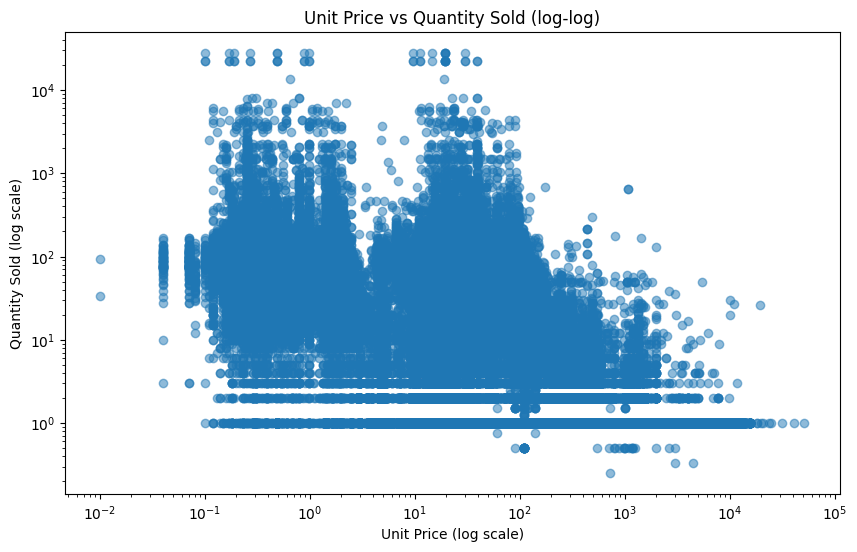

In [675]:
# plot unitprice vs quantity with log scale
x = products['unitprice'].clip(lower=1e-6)
y = products['quantity'].clip(lower=1e-6)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.5)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Unit Price (log scale)')
plt.ylabel('Quantity Sold (log scale)')
plt.title('Unit Price vs Quantity Sold (log-log)')
plt.show()

In [671]:
df_tmp = products.groupby('product_id').agg(change_in_quantity=('quantity', 'std'),
                                            change_in_unit_price=('unitprice', 'std'))

In [682]:
df_tmp = df_tmp.query('change_in_unit_price > 0')
df_tmp['price_elasticity'] = df_tmp['change_in_quantity'] / df_tmp['change_in_unit_price']
df_tmp['price_elasticity'].describe()

count      1267.000000
mean        597.422618
std       19292.367966
min           0.000000
25%           0.000000
50%           0.000000
75%           0.018489
max      686300.000000
Name: price_elasticity, dtype: float64

#### 3. Customer Structure Analysis


In [687]:
customers_analysis = customers_with_parent.copy()
# Convert positive if number_patient is negeative
customers_analysis['number_patients'] = customers_analysis['number_patients'].abs()
customers_analysis.number_patients = customers_analysis.number_patients.fillna(0).astype(int)
# bin number of patients
bins = [0, 1, 10, 50, 100, 500, 1000, 5000, 10000, np.inf]
labels = ['0', '1-10', '11-50', '51-100', '101-500', '501-1k', '1k-5k', '5k-10k', '10k+']
customers_analysis['size_category'] = pd.cut(customers_analysis['number_patients'], bins=bins, labels=labels, right=False)

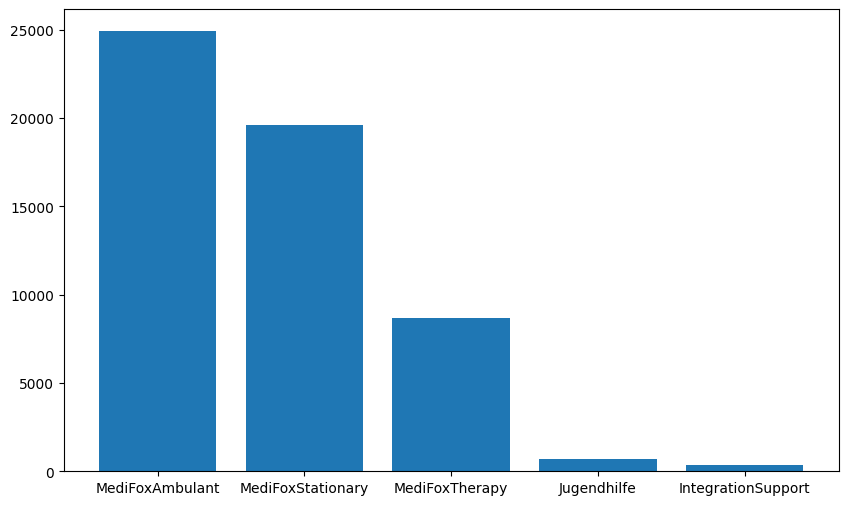

In [695]:
# barplot for the above
plt.figure(figsize=(10, 6))
plt.bar(customers_analysis['business_unit'].value_counts().index,
        customers_analysis['business_unit'].value_counts().values)
plt.show()

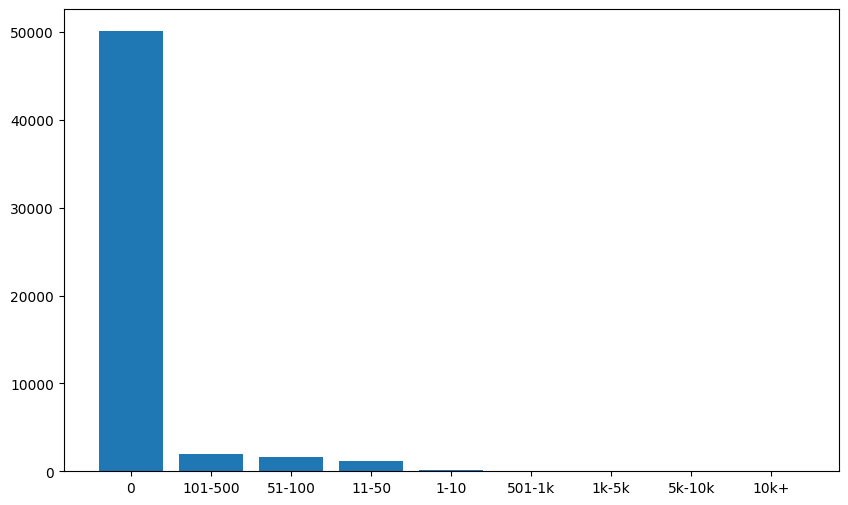

In [696]:
# barplot for the above
plt.figure(figsize=(10, 6))
plt.bar(customers_analysis['size_category'].value_counts().index,
        customers_analysis['size_category'].value_counts().values)
plt.show()

In [703]:
customers_analysis.query('billing_address != shipping_address').shape

(5822, 13)

In [705]:
customers_analysis.shipping_address.value_counts()

shipping_address
5F2E2AD3557CD9F88BD05    536
1FC05CB47180BC7E772C0    237
21B1A9136BC1971B509E2     93
92A63F5051DF117230845     46
10B7D3AC397892E762F06     32
                        ... 
197484108440EAA65B107      1
3C728F07F5F97ABE7492F      1
5B8E9A24BED51928F4B9E      1
3CC31C43D96ED999C5EB1      1
EAA9136BF07D8DAD263FE      1
Name: count, Length: 43358, dtype: int64

In [693]:
df_vis =df.groupby('closedate').agg(total_revenue=('totalprice', 'sum'),
                            num_deals=('product_category', 'count'))

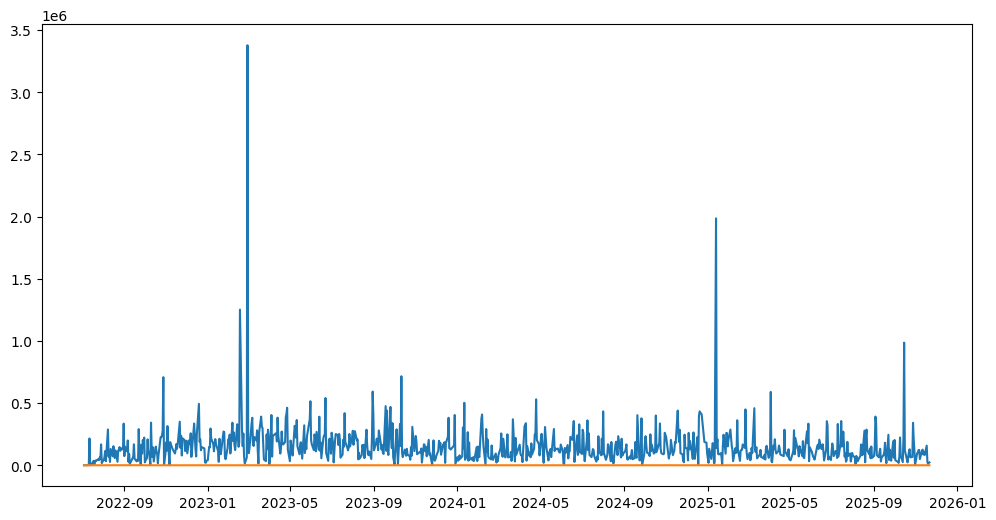

In [694]:
# using df_vis plot total_revenue and num_deals over time
plt.figure(figsize=(12, 6))
plt.plot(df_vis.index, df_vis.total_revenue)
plt.plot(df_vis.index, df_vis.num_deals)
plt.show()

In [ ]:
customers_analysis.